**Predict product sales from TV, radio and newspaper ad spend, and identify which channels are most effective**

In [33]:
# data analysis
import pandas as pd
import numpy as np

# visualization
import seaborn as sns
import matplotlib.pyplot as plt

# machine learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

## Acquire data

In [10]:
df = pd.read_csv("/content/advertising.csv")

###How data looks like

In [11]:
# Train
df.sample(5)

,TV,Radio,Newspaper,Sales
39,228.0,37.7,32.0,21.5
56,7.3,28.1,41.4,5.5
33,265.6,20.0,0.3,17.4
42,293.6,27.7,1.8,20.7
21,237.4,5.1,23.5,17.5


### How big is the data

In [12]:
# Train
df.shape

(200, 4)

Each of the 200 rows is a different market

###How does the data looks mathematically

In [13]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


###What is datatype

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


**Which features are categorical?**
 nominal, ordinal, ratio, or interval based

No categorical featurs.

**Which features are numerical?**
discrete, continuous, or timeseries based

All featurs are continuous variable.

**Which features are mixed data types** Numerical, alphanumeric data within same feature

NA.

###Any missing values?

In [15]:
df.isnull().sum()

,0
TV,0
Radio,0
Newspaper,0
Sales,0


###Any duplicate rows

In [16]:
df.duplicated().sum()

np.int64(0)

###Train test split

In [17]:
X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

###Check the distribution of input featurs

**TV**

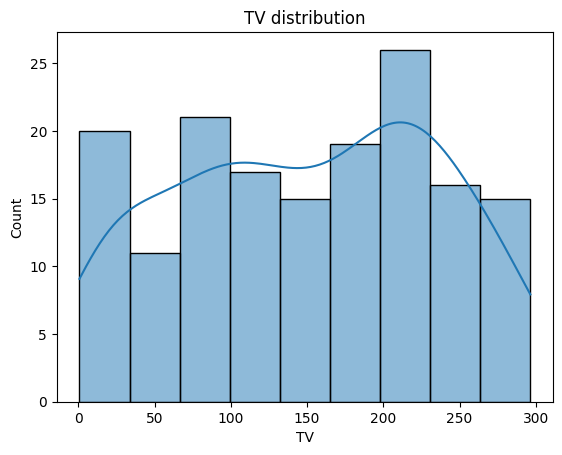

In [18]:
sns.histplot(X_train["TV"],kde="true")
plt.title("TV distribution")
plt.show()

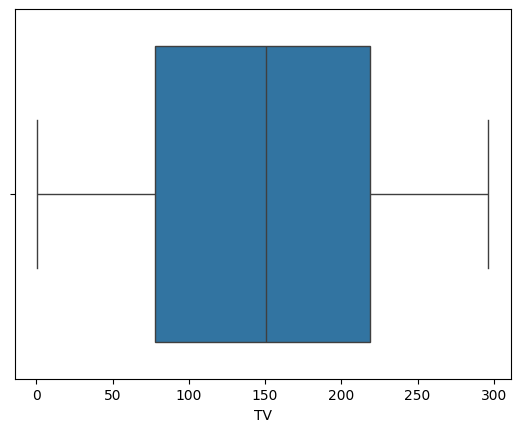

In [19]:
sns.boxplot(x=X_train["TV"])
plt.show()

No outliers

Radio

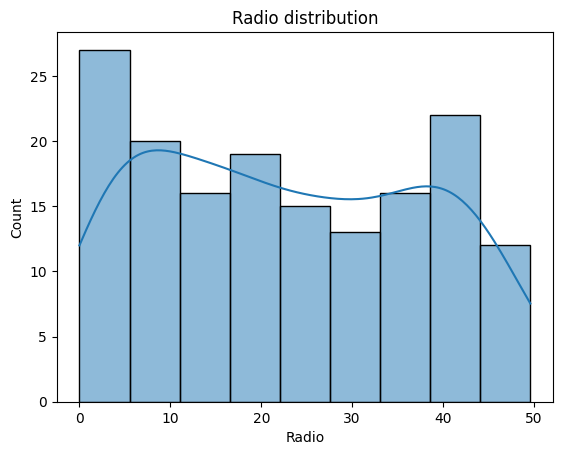

In [20]:
sns.histplot(X_train["Radio"], kde=True)
plt.title("Radio distribution")
plt.show()

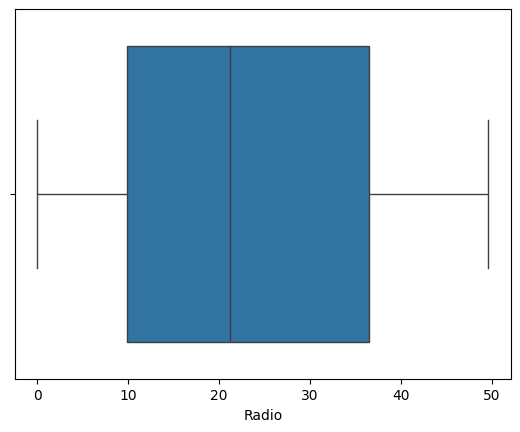

In [21]:
sns.boxplot(x=X_train["Radio"])
plt.show()

No outliers

Newspapers

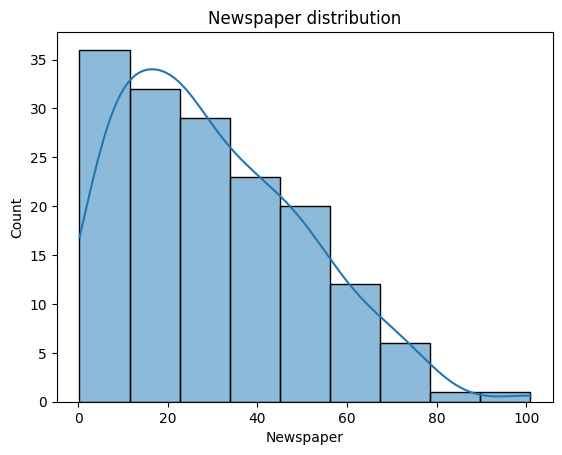

In [22]:
sns.histplot(X_train["Newspaper"], kde=True)
plt.title("Newspaper distribution")
plt.show()

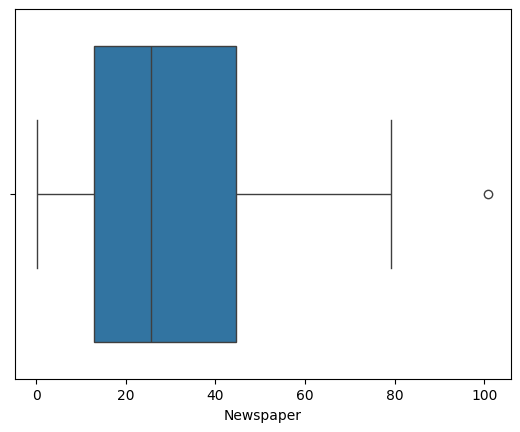

In [23]:
sns.boxplot(x=X_train["Newspaper"])
plt.show()

observed one outlier

Sales

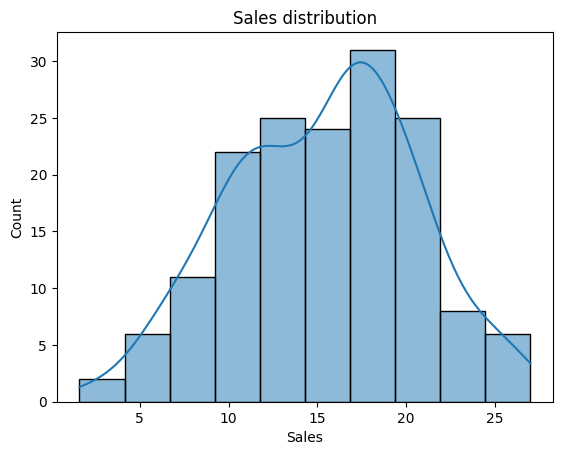

In [24]:
sns.histplot(y_train, kde=True)
plt.title("Sales distribution")
plt.show()

**TV Vs Sales**

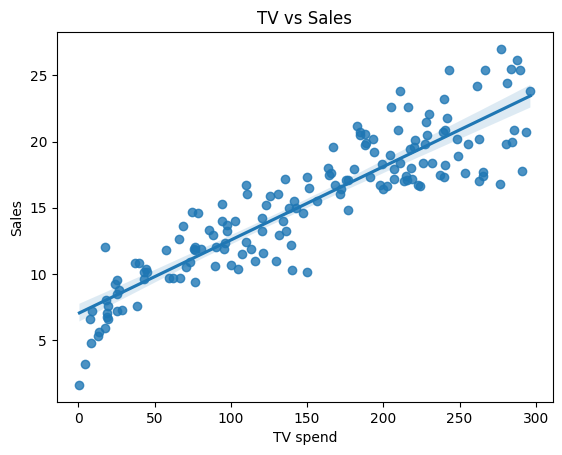

In [25]:
sns.regplot(x=X_train["TV"], y=y_train)
plt.title("TV vs Sales")
plt.xlabel("TV spend")
plt.ylabel("Sales")
plt.show()

**Radio Vs Sales**

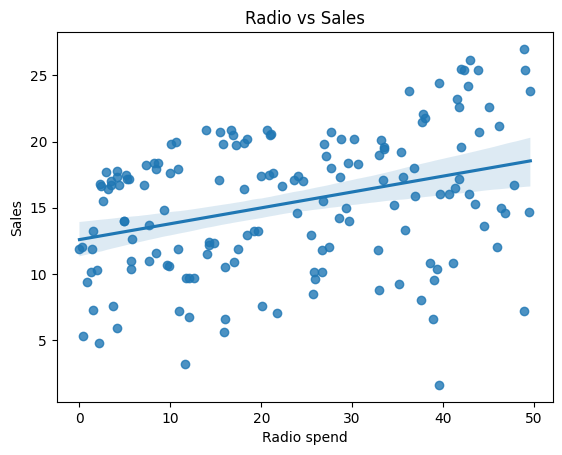

In [26]:
sns.regplot(x=X_train["Radio"], y=y_train)
plt.title("Radio vs Sales")
plt.xlabel("Radio spend")
plt.ylabel("Sales")
plt.show()

Newspapers Vs Sales

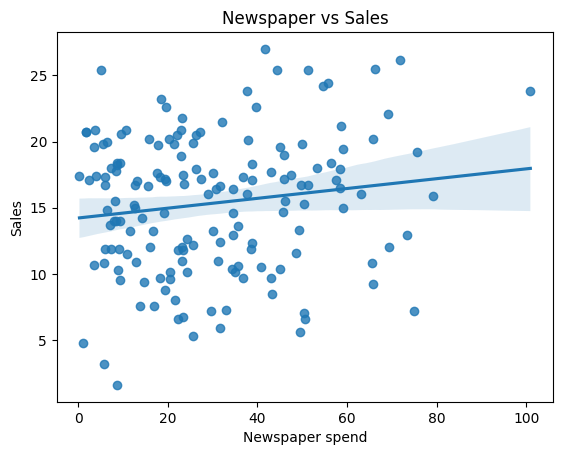

In [27]:
sns.regplot(x=X_train["Newspaper"], y=y_train)
plt.title("Newspaper vs Sales")
plt.xlabel("Newspaper spend")
plt.ylabel("Sales")
plt.show()

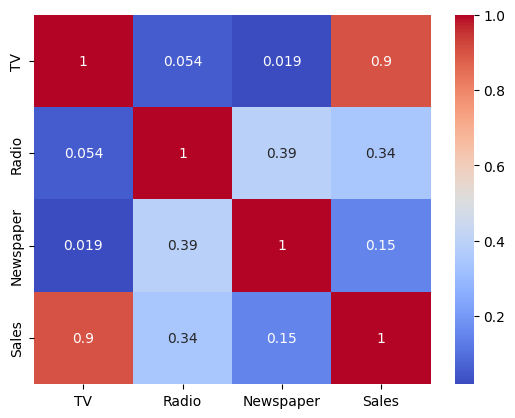

In [28]:
# Correlation between features, and with Sales
sns.heatmap(X_train.assign(Sales=y_train).corr(), annot=True, cmap="coolwarm")
plt.show()

In [29]:

# Multicollinearity (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

Xc = sm.add_constant(X_train)
for i, col in enumerate(Xc.columns):
    print(col, variance_inflation_factor(Xc.values, i))

const 1.0
TV 1.002914615243479
Radio 1.1803053248476272
Newspaper 1.177308592350459


Strong co relation between TV and sales, most of the prediction comes from the TV.
Very less co relationship between features to fetures, Multiple Regression can be used

All input featurs seems to have linear relationshio between sales, ML alorithm to be use is multiple regression.

### Model building

In [30]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
for name, coef in zip(X_train.columns, model.coef_):
    print(name, coef)

Intercept: 4.714126402214127
TV 0.05450927083721978
Radio 0.10094536239295579
Newspaper 0.0043366468220340446


In [31]:
# 2. Predict on the test set
y_pred = model.predict(X_test)

In [32]:
new_data = pd.DataFrame({"TV": [150], "Radio": [30], "Newspaper": [20]})
print(model.predict(new_data))

[16.00561084]


### Evaluate the model

In [34]:
print("R2:", r2_score(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("MAE:", mean_absolute_error(y_test, y_pred))

R2: 0.9059011844150826
RMSE: 1.7052146229349223
MAE: 1.2748262109549338
